# Análise de Redes e Conexões
**Rede de co-ocorrência de personagens de *Os Miseráveis* (Victor Hugo)** — mapeamento, centralidade, comunidades e hubs com NetworkX.

Cada **nó** é um personagem e cada **aresta** liga dois personagens que aparecem juntos em um mesmo capítulo (o **peso** é o número de capítulos compartilhados). Usamos esse dataset público (Knuth, *Stanford GraphBase*) como proxy de uma rede social.

**Etapas:** 1) dataset · 2) grafo · 3) centralidade · 4) visualização · 5) comunidades e hubs · 6) robustez.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("networkx", nx.__version__, "| pandas", pd.__version__)

networkx 3.7 | pandas 3.1.0


## 1. Dataset de conexões
**Objetivo:** obter a edge list (`source`, `target`, `weight`), limpá-la com Pandas e documentar o tamanho antes/depois.

O dataset vem embutido no NetworkX (sem download). Na primeira execução ele é exportado para `data/edges_raw.csv`; depois disso, o notebook lê sempre o CSV.

In [2]:
RAW = DATA / "edges_raw.csv"
if not RAW.exists():
    g0 = nx.les_miserables_graph()
    pd.DataFrame(
        [(u, v, d["weight"]) for u, v, d in g0.edges(data=True)],
        columns=["source", "target", "weight"],
    ).to_csv(RAW, index=False)

edges_raw = pd.read_csv(RAW)
edges_raw.head()

,source,target,weight
0,Napoleon,Myriel,1
1,Myriel,MlleBaptistine,8
2,Myriel,MmeMagloire,10
3,Myriel,CountessDeLo,1
4,Myriel,Geborand,1


In [3]:
def clean_edges(df: pd.DataFrame) -> pd.DataFrame:
    """Remove nulos, self-loops e duplicatas (tratando A-B igual a B-A)."""
    df = df.dropna(subset=["source", "target"]).copy()
    df["source"], df["target"] = df["source"].str.strip(), df["target"].str.strip()
    df = df[df["source"] != df["target"]]
    a = df[["source", "target"]].min(axis=1); b = df[["source", "target"]].max(axis=1)
    df["source"], df["target"] = a, b
    return (df.groupby(["source", "target"], as_index=False)["weight"].sum()
              .sort_values(["source", "target"]).reset_index(drop=True))

edges = clean_edges(edges_raw)
resumo = pd.DataFrame({
    "arestas": [len(edges_raw), len(edges)],
    "nós únicos": [pd.unique(edges_raw[["source", "target"]].values.ravel()).size,
                   pd.unique(edges[["source", "target"]].values.ravel()).size],
    "nulos": [int(edges_raw.isna().any(axis=1).sum()), int(edges.isna().any(axis=1).sum())],
}, index=["bruto", "tratado"])
edges.to_csv(DATA / "edges_clean.csv", index=False)
resumo

,arestas,nós únicos,nulos
bruto,254,77,0
tratado,254,77,0


> **Insight:** o dataset já era consistente: 254 arestas e 77 nós antes e depois da limpeza, sem nulos, self-loops ou duplicatas. Mesmo assim o pipeline de limpeza fica no notebook para valer com dados novos.

## 2. Construção do grafo
**Objetivo:** construir o grafo e resumir sua estrutura global.

Escolha: **`Graph` não direcionado e ponderado**. Co-aparecer em um capítulo é uma relação simétrica, então não há direção a modelar.

In [4]:
G = nx.from_pandas_edgelist(edges, "source", "target", edge_attr="weight")

def graph_summary(G: nx.Graph) -> pd.Series:
    """Métricas globais; diâmetro calculado na maior componente conectada."""
    comps = list(nx.connected_components(G))
    lcc = G.subgraph(max(comps, key=len))
    return pd.Series({
        "nós": G.number_of_nodes(),
        "arestas": G.number_of_edges(),
        "densidade": nx.density(G),
        "grau médio": 2 * G.number_of_edges() / G.number_of_nodes(),
        "componentes conectados": len(comps),
        "diâmetro (maior componente)": nx.diameter(lcc),
        "caminho médio (maior componente)": nx.average_shortest_path_length(lcc),
        "clustering médio": nx.average_clustering(G),
        "transitividade": nx.transitivity(G),
    })

summary = graph_summary(G)
summary.to_frame("valor").to_csv(OUT / "resumo_rede.csv")
summary.to_frame("valor")

,valor
nós,77.0000
arestas,254.0000
densidade,0.0868
grau médio,6.5974
componentes conectados,1.0000
diâmetro (maior componente),5.0000
caminho médio (maior componente),2.6411
clustering médio,0.5731
transitividade,0.4989


> **Insight:** é uma rede **conectada** (1 componente), **esparsa** (densidade 0,087; grau médio 6,6) e, ao mesmo tempo, **muito agrupada** (clustering médio 0,57; transitividade 0,50). Com diâmetro 5 e caminho médio 2,6, qualquer personagem chega a qualquer outro em poucos saltos. Isso é o padrão de *mundo pequeno*: grupos coesos ligados por poucos atalhos.

## 3. Centralidade
**Objetivo:** medir a importância de cada nó sob quatro óticas (mais PageRank):
- **Grau**: quantas conexões diretas o nó tem.
- **Intermediação (betweenness)**: quanto o nó fica "no caminho" entre os outros (ponte).
- **Proximidade (closeness)**: quão perto o nó está de todos os demais.
- **Autovetor (eigenvector)**: ter conexões com nós também importantes.

Para intermediação e proximidade, o peso (nº de capítulos) é uma *força* de laço, não uma distância. Por isso usamos caminhos por número de saltos, sem peso.

In [5]:
def centrality_table(G: nx.Graph) -> pd.DataFrame:
    return pd.DataFrame({
        "grau": dict(G.degree()),
        "grau_ponderado": dict(G.degree(weight="weight")),
        "centralidade_grau": nx.degree_centrality(G),
        "intermediacao": nx.betweenness_centrality(G, normalized=True),
        "proximidade": nx.closeness_centrality(G),
        "autovetor": nx.eigenvector_centrality(G, max_iter=1000),
        "pagerank": nx.pagerank(G, weight="weight"),
    })

cent = centrality_table(G)
cent.sort_values("grau", ascending=False).to_csv(OUT / "centralidades.csv", index_label="personagem")
top10 = cent.sort_values("centralidade_grau", ascending=False).head(10)
top10.to_csv(OUT / "top10_centralidade_grau.csv", index_label="personagem")
top10

,grau,grau_ponderado,centralidade_grau,intermediacao,proximidade,autovetor,pagerank
Valjean,36,158,0.4737,0.5700,0.6441,0.2676,0.0996
Gavroche,22,56,0.2895,0.1651,0.5135,0.3178,0.0283
Marius,19,104,0.2500,0.1320,0.5315,0.2591,0.0517
Javert,17,47,0.2237,0.0543,0.5170,0.1842,0.0268
Thenardier,16,61,0.2105,0.0749,0.5170,0.1878,0.0357
Enjolras,15,91,0.1974,0.0426,0.4810,0.2672,0.0366
Fantine,15,47,0.1974,0.1296,0.4606,0.0898,0.0272
Courfeyrac,13,84,0.1711,0.0053,0.4000,0.2325,0.0330
Bossuet,13,66,0.1711,0.0308,0.4750,0.2421,0.0262
Joly,12,43,0.1579,0.0022,0.3938,0.2216,0.0177


In [6]:
# Top 10 por métrica, lado a lado
metricas = ["centralidade_grau", "intermediacao", "proximidade", "autovetor"]
lado_a_lado = pd.DataFrame({m: cent[m].nlargest(10).index.to_list() for m in metricas}, index=range(1, 11))
lado_a_lado.index.name = "posição"
lado_a_lado

,centralidade_grau,intermediacao,proximidade,autovetor
posição,,,,
1,Valjean,Valjean,Valjean,Gavroche
2,Gavroche,Myriel,Marius,Valjean
3,Marius,Gavroche,Thenardier,Enjolras
4,Javert,Marius,Javert,Marius
5,Thenardier,Fantine,Gavroche,Bossuet
6,Enjolras,Thenardier,Enjolras,Courfeyrac
7,Fantine,Javert,Cosette,Bahorel
8,Bossuet,MlleGillenormand,Bossuet,Joly
9,Courfeyrac,Enjolras,Babet,Combeferre


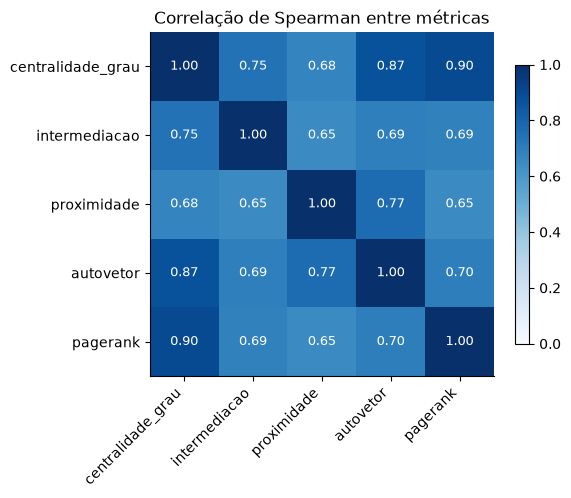

In [7]:
# Correlação de Spearman entre os rankings
corr = cent[metricas + ["pagerank"]].corr(method="spearman")
corr.to_csv(OUT / "correlacao_spearman.csv")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if corr.iloc[i, j] > 0.6 else "black", fontsize=9)
ax.set_title("Correlação de Spearman entre métricas"); fig.colorbar(im, shrink=0.8)
fig.tight_layout(); fig.savefig(OUT / "correlacao_metricas.png", dpi=200); plt.show()

In [8]:
# Onde os rankings divergem: maior diferença de posição entre grau e intermediação
rank = cent[metricas].rank(ascending=False, method="min").astype(int)
rank["dif_grau_vs_interm"] = rank["centralidade_grau"] - rank["intermediacao"]
pd.concat([rank.sort_values("dif_grau_vs_interm").head(5), rank.sort_values("dif_grau_vs_interm").tail(5)])

,centralidade_grau,intermediacao,proximidade,autovetor,dif_grau_vs_interm
Bahorel,10,27,36,7,-17
Combeferre,12,29,43,9,-17
Joly,10,27,36,7,-17
Feuilly,12,29,43,9,-17
Grantaire,18,34,49,13,-16
Scaufflaire,61,35,36,52,26
OldMan,61,35,68,70,26
Napoleon,61,35,68,70,26
Fauchelevent,42,14,28,39,28
MmeBurgon,51,15,54,50,36


> **Insight:** **Valjean** domina em grau (36), intermediação (0,57) e proximidade, e é o centro da rede em todas as métricas. Os rankings concordam em linhas gerais (Spearman 0,65 a 0,90), mas divergem em pontos úteis: o grupo de estudantes (Bahorel, Combeferre, Joly, Feuilly) tem muitas conexões, quase todas entre si, e cai 17 posições em intermediação. Já personagens de grau baixo, como Mme Burgon, Fauchelevent e Napoleon, sobem 26 a 36 posições porque ligam trechos que não se tocam de outra forma. **Grau mede popularidade; intermediação mede quem une grupos.** Gavroche lidera em autovetor porque se conecta a pessoas bem conectadas.

## 4. Visualização
**Objetivo:** desenhar a rede com layout *force-directed* (Fruchterman-Reingold, `seed` fixa), com tamanho do nó proporcional à centralidade e cor por comunidade.

Como a cor depende das comunidades, elas são detectadas aqui com **Louvain** (detalhadas na seção 5).

In [9]:
def detect_communities(G: nx.Graph, seed: int = SEED):
    comms = nx.community.louvain_communities(G, weight="weight", seed=seed)
    comms = sorted(comms, key=len, reverse=True)           # comunidade 0 = maior
    mapping = {n: i for i, c in enumerate(comms) for n in c}
    return comms, mapping, nx.community.modularity(G, comms, weight="weight")

communities, comm_of, Q = detect_communities(G)
cent["comunidade"] = pd.Series(comm_of)
print(f"{len(communities)} comunidades | modularidade Q = {Q:.4f}")

6 comunidades | modularidade Q = 0.5654


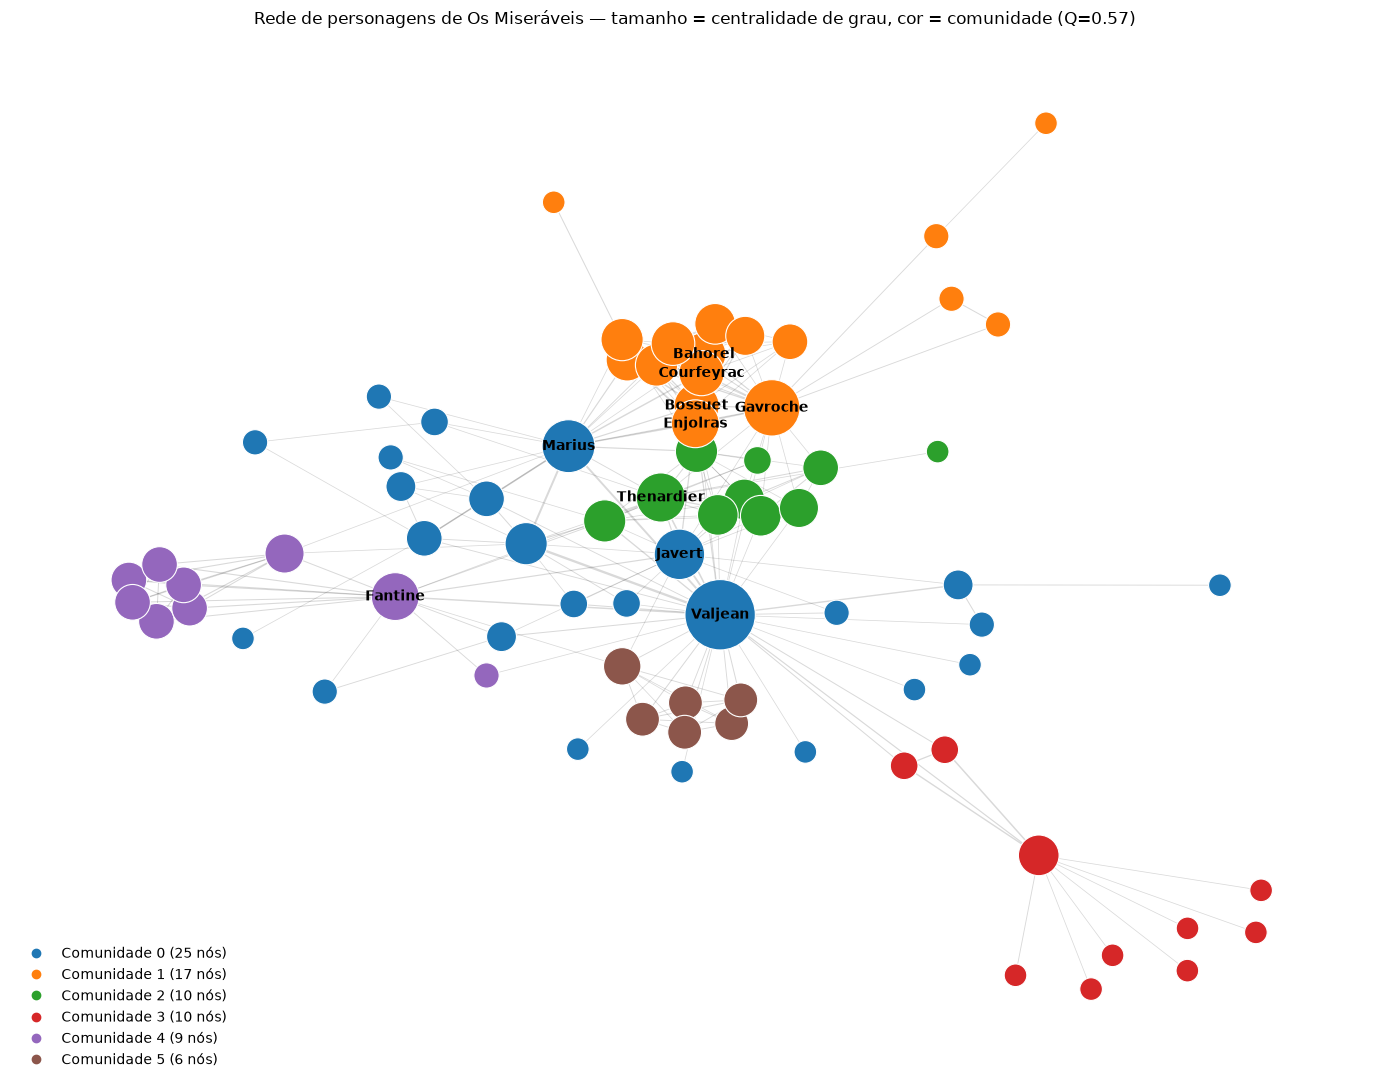

In [10]:
pos = nx.spring_layout(G, k=0.35, iterations=200, weight=None, seed=SEED)
palette = plt.get_cmap("tab10")
node_colors = [palette(comm_of[n] % 10) for n in G.nodes]
node_sizes = [200 + 5000 * cent.loc[n, "centralidade_grau"] for n in G.nodes]
hubs = cent["centralidade_grau"].nlargest(10).index

fig, ax = plt.subplots(figsize=(14, 11))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.15,
                       width=[0.3 + 0.25 * G[u][v]["weight"] ** 0.5 for u, v in G.edges])
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=node_sizes,
                       edgecolors="white", linewidths=0.8)
nx.draw_networkx_labels(G, pos, labels={n: n for n in hubs}, font_size=10, font_weight="bold", ax=ax)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=palette(i % 10),
                          label=f"Comunidade {i} ({len(c)} nós)") for i, c in enumerate(communities)],
          loc="lower left", frameon=False)
ax.set_title(f"Rede de personagens de Os Miseráveis — tamanho = centralidade de grau, cor = comunidade (Q={Q:.2f})")
ax.axis("off"); fig.tight_layout()
fig.savefig(OUT / "rede_force_directed.png", dpi=200); plt.show()

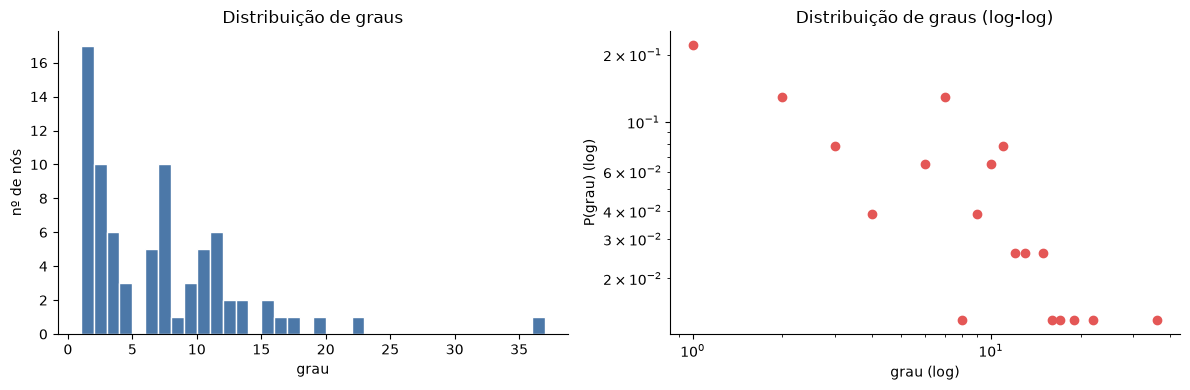

mediana = 6 | média = 6.60 | máximo = 36 (Valjean)


In [11]:
# Distribuição de graus (linear e log-log)
deg = pd.Series(dict(G.degree()))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(deg, bins=range(1, deg.max() + 2), color="#4c78a8", edgecolor="white")
axes[0].set(title="Distribuição de graus", xlabel="grau", ylabel="nº de nós")
cnt = deg.value_counts().sort_index()
axes[1].loglog(cnt.index, cnt.values / cnt.sum(), "o", color="#e45756")
axes[1].set(title="Distribuição de graus (log-log)", xlabel="grau (log)", ylabel="P(grau) (log)")
fig.tight_layout(); fig.savefig(OUT / "distribuicao_graus.png", dpi=200); plt.show()
print(f"mediana = {deg.median():.0f} | média = {deg.mean():.2f} | máximo = {deg.max()} ({deg.idxmax()})")

> **Insight:** o desenho separa visualmente os grupos: estudantes revolucionários (laranja), família Thénardier (verde), o círculo de Fantine (roxo), o julgamento de Champmathieu (marrom) e o entorno do bispo Myriel (vermelho). Valjean fica no centro, ligando quase tudo. A distribuição de graus é assimétrica (mediana 6, máximo 36): a maioria tem poucas conexões e poucos nós concentram muitas. Com apenas 77 nós, não é possível afirmar que segue uma lei de potência.

## 5. Comunidades e hubs
**Objetivo:** caracterizar cada comunidade, identificar **hubs** (alto grau) e **pontes** (alto intermediação com ligações para fora da própria comunidade).

In [12]:
def community_report(G, communities, cent, top_n=5) -> pd.DataFrame:
    rows = []
    for i, c in enumerate(communities):
        sub = cent.loc[sorted(c)].sort_values("grau", ascending=False, kind="stable")  # desempate determinístico (ordem alfabética)
        rows.append({
            "comunidade": i, "tamanho": len(c),
            "principais membros (por grau)": ", ".join(sub.index[:top_n]),
            "grau médio": sub["grau"].mean(),
            "densidade interna": nx.density(G.subgraph(c)),
        })
    return pd.DataFrame(rows).set_index("comunidade")

rep = community_report(G, communities, cent)
rep.to_csv(OUT / "comunidades.csv")
print(f"Modularidade (Louvain): {Q:.4f}")
rep

Modularidade (Louvain): 0.5654


,tamanho,principais membros (por grau),grau médio,densidade interna
comunidade,,,,
0,25,"Valjean, Marius, Javert, Cosette, Gillenormand",5.4800,0.1467
1,17,"Gavroche, Enjolras, Bossuet, Courfeyrac, Bahorel",9.0588,0.4853
2,10,"Thenardier, Eponine, MmeThenardier, Babet, Cla...",8.8000,0.6667
3,10,"Myriel, MlleBaptistine, MmeMagloire, Champterc...",2.3000,0.2222
4,9,"Fantine, Tholomyes, Blacheville, Dahlia, Fameuil",7.5556,0.8056
5,6,"Bamatabois, Brevet, Champmathieu, Chenildieu, ...",6.3333,1.0000


In [13]:
# Hubs e pontes
def cross_ratio(n) -> float:
    """Fração das conexões do nó que vão para outra comunidade."""
    nb = list(G.neighbors(n))
    return sum(comm_of[m] != comm_of[n] for m in nb) / len(nb)

cent["fracao_externa"] = [cross_ratio(n) for n in cent.index]
hubs_df = cent.nlargest(10, "grau")[["grau", "intermediacao", "comunidade", "fracao_externa"]]
pontes_df = (cent[cent["grau"] >= 3].nlargest(10, "intermediacao")
             [["grau", "intermediacao", "comunidade", "fracao_externa"]])
hubs_df.to_csv(OUT / "hubs.csv", index_label="personagem"); pontes_df.to_csv(OUT / "pontes.csv", index_label="personagem")
display(hubs_df.style.set_caption("Hubs (maior grau)"))
display(pontes_df.style.set_caption("Pontes (maior intermediação, grau ≥ 3)"))

,grau,intermediacao,comunidade,fracao_externa
Valjean,36,0.569989,0,0.555556
Gavroche,22,0.165113,1,0.363636
Marius,19,0.132032,0,0.631579
Javert,17,0.054332,0,0.588235
Thenardier,16,0.074901,2,0.437500
Enjolras,15,0.042553,1,0.266667
Fantine,15,0.129645,4,0.466667
Bossuet,13,0.030754,1,0.153846
Courfeyrac,13,0.005267,1,0.153846
Bahorel,12,0.002185,1,0.083333


,grau,intermediacao,comunidade,fracao_externa
Valjean,36,0.569989,0,0.555556
Myriel,10,0.176842,3,0.100000
Gavroche,22,0.165113,1,0.363636
Marius,19,0.132032,0,0.631579
Fantine,15,0.129645,4,0.466667
Thenardier,16,0.074901,2,0.437500
Javert,17,0.054332,0,0.588235
MlleGillenormand,7,0.047599,0,0.000000
Enjolras,15,0.042553,1,0.266667
Tholomyes,9,0.040629,4,0.222222


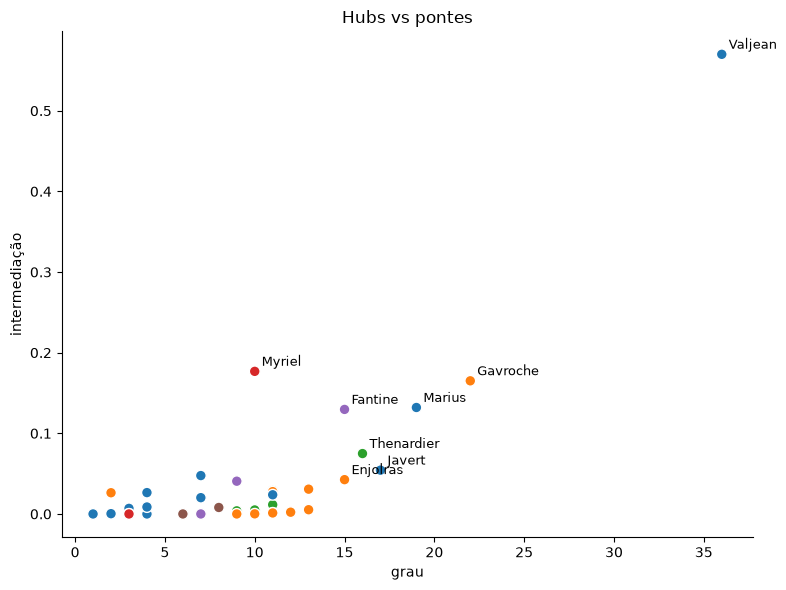

In [14]:
# Hubs x pontes: grau vs intermediação, colorido por comunidade
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(cent["grau"], cent["intermediacao"], c=[palette(c % 10) for c in cent["comunidade"]],
           s=60, edgecolors="white")
for n in set(cent["grau"].nlargest(6).index) | set(cent["intermediacao"].nlargest(6).index):
    ax.annotate(n, (cent.loc[n, "grau"], cent.loc[n, "intermediacao"]), fontsize=9,
                xytext=(5, 4), textcoords="offset points")
ax.set(xlabel="grau", ylabel="intermediação", title="Hubs vs pontes")
fig.tight_layout(); fig.savefig(OUT / "hubs_vs_pontes.png", dpi=200); plt.show()

> **Insight:** o Louvain encontrou **6 comunidades** com modularidade **Q = 0,57**, o que indica uma divisão bem marcada. Os grupos são pequenos e muito coesos: a cena do julgamento tem densidade interna 1,0 (todos se conhecem) e o círculo de Fantine 0,81. Os **hubs** de cada grupo são Valjean, Gavroche, Thénardier e Fantine. As **pontes** não coincidem com os hubs: Valjean, Myriel, Marius e Fantine têm intermediação alta. **Myriel** (grau 10, 2ª maior intermediação) é quase só uma ponte, pois seu círculo se liga ao resto da rede por pouquíssimos caminhos.

## 6. Teste de robustez (opcional)
**Objetivo:** o que acontece se os hubs saírem da rede? Comparamos remover os nós de maior grau (ataque direcionado) com remover nós aleatórios (falha), medindo a fração de nós que permanece na maior componente conectada.

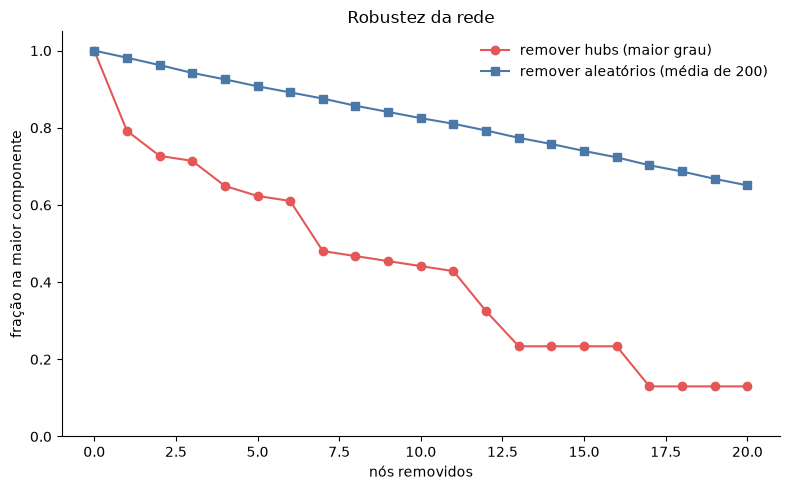

,hubs,aleatório
removidos,,
0,1.0000,1.0000
1,0.7922,0.9817
3,0.7143,0.9422
5,0.6234,0.9075
10,0.4416,0.8250
20,0.1299,0.6508


In [15]:
def lcc_fraction(H: nx.Graph, n0: int) -> float:
    return len(max(nx.connected_components(H), key=len)) / n0 if len(H) else 0.0

def attack_curve(G, order, kmax):
    H, n0, out = G.copy(), G.number_of_nodes(), [lcc_fraction(G, G.number_of_nodes())]
    for n in order[:kmax]:
        H.remove_node(n); out.append(lcc_fraction(H, n0))
    return out

K = 20
alvo = attack_curve(G, list(cent["grau"].sort_values(ascending=False, kind="stable").index), K)
rng = np.random.default_rng(SEED)
aleat = np.mean([attack_curve(G, list(rng.permutation(G.nodes)), K) for _ in range(200)], axis=0)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(K + 1), alvo, "o-", color="#e45756", label="remover hubs (maior grau)")
ax.plot(range(K + 1), aleat, "s-", color="#4c78a8", label="remover aleatórios (média de 200)")
ax.set(xlabel="nós removidos", ylabel="fração na maior componente", title="Robustez da rede", ylim=(0, 1.05))
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(OUT / "robustez.png", dpi=200); plt.show()
pd.DataFrame({"removidos": [0, 1, 3, 5, 10, 20], "hubs": [alvo[k] for k in (0, 1, 3, 5, 10, 20)],
              "aleatório": [aleat[k] for k in (0, 1, 3, 5, 10, 20)]}).set_index("removidos")

> **Insight:** a rede resiste bem a falhas aleatórias e mal a ataques aos hubs. Remover só **Valjean** deixa 79% dos nós na maior componente; remover os **20 maiores hubs** deixa 13%, contra 65% quando os 20 nós são sorteados. Em linguagem de negócio: a coesão da rede depende de poucas pessoas-chave, então é nelas que se concentra o risco (e a oportunidade de influência).

## Resumo executivo
- **Rede:** 77 personagens e 254 conexões, conectada, esparsa (densidade 0,087) e com clustering alto (0,57): perfil de mundo pequeno (caminho médio 2,6; diâmetro 5).
- **Hub principal:** Valjean (grau 36, intermediação 0,57), seguido por Gavroche (22), Marius (19), Javert (17) e Thénardier (16).
- **Comunidades:** o Louvain achou 6 grupos (Q = 0,57) correspondentes a episódios do enredo, de 6 a 25 personagens.
- **Pontes:** Valjean, Myriel, Gavroche, Marius e Fantine ligam os grupos; ponte nem sempre é hub (Myriel).
- **Métricas divergem:** grau mede popularidade e intermediação mede articulação; o grupo de estudantes é popular, mas pouco ponte.
- **Robustez:** removendo os 20 maiores hubs sobra 13% da rede conectada, contra 65% na remoção aleatória.
- **Limitação:** a rede é de co-ocorrência em capítulos, não de interações sociais reais, e tem só 77 nós; conclusões sobre distribuição de graus são exploratórias.